<a href="https://colab.research.google.com/github/shivansh11s/Neuro-Scan-AI/blob/main/BT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import gc
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import numpy as np

gc.collect()
torch.cuda.empty_cache()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"shivansh11s","key":"1f2480797b540a74863dfd48296b4717"}'}

In [ ]:
!pip install -q kaggle
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

!kaggle datasets download -d masoudnickparvar/brain-tumor-mri-dataset
!unzip -q -o brain-tumor-mri-dataset.zip -d dataset/

Dataset URL: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 157M/157M [00:11<00:00, 14.0MB/s]



In [ ]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

full_data = datasets.ImageFolder(root='dataset/Training', transform=transform)

total_len = len(full_data)
train_len = int(0.8 * total_len)
val_len = int(0.1 * total_len)
test_len = total_len - train_len - val_len

train_data, val_data, test_data = random_split(full_data, [train_len, val_len, test_len])

train_loader = DataLoader(train_data, batch_size=16, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_data, batch_size=16, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_data, batch_size=16, shuffle=False, num_workers=2, pin_memory=True)

In [ ]:
class UNetEncoder(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(UNetEncoder, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.conv(x)

class UNetDecoder(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(UNetDecoder, self).__init__()
        self.up = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)
        self.conv = UNetEncoder(in_channels, out_channels)

    def forward(self, x1, x2):
        x1 = self.up(x1)
        diffY = x2.size()[2] - x1.size()[2]
        diffX = x2.size()[3] - x1.size()[3]
        x1 = F.pad(x1, [diffX // 2, diffX - diffX // 2, diffY // 2, diffY - diffY // 2])
        return self.conv(torch.cat([x2, x1], dim=1))

class ViTBottleneck(nn.Module):
    def __init__(self, embed_dim=512, num_heads=8, num_layers=4):
        super(ViTBottleneck, self).__init__()
        encoder_layer = nn.TransformerEncoderLayer(d_model=embed_dim, nhead=num_heads)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

    def forward(self, x):
        B, C, H, W = x.shape
        x = x.view(B, C, H * W).permute(2, 0, 1)
        x = self.transformer(x)
        x = x.permute(1, 2, 0).view(B, C, H, W)
        return x

class HybridUNetViT(nn.Module):
    def __init__(self, n_classes):
        super(HybridUNetViT, self).__init__()
        self.enc1 = UNetEncoder(3, 64)
        self.enc2 = UNetEncoder(64, 128)
        self.enc3 = UNetEncoder(128, 256)
        self.enc4 = UNetEncoder(256, 512)

        self.vit = ViTBottleneck(embed_dim=512)

        self.dec1 = UNetDecoder(512, 256)
        self.dec2 = UNetDecoder(256, 128)
        self.dec3 = UNetDecoder(128, 64)

        self.seg_head = nn.Conv2d(64, 1, kernel_size=1)
        self.cls_head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(64, n_classes)
        )

    def forward(self, x):
        x1 = self.enc1(x)
        x2 = self.enc2(F.max_pool2d(x1, 2))
        x3 = self.enc3(F.max_pool2d(x2, 2))
        x4 = self.enc4(F.max_pool2d(x3, 2))

        x_vit = self.vit(x4)

        x = self.dec1(x_vit, x3)
        x = self.dec2(x, x2)
        x = self.dec3(x, x1)

        seg_output = torch.sigmoid(self.seg_head(x))
        cls_output = self.cls_head(x)
        return seg_output, cls_output

##The model is trained and saved in the path /document/drive/MyDrive/best_hybrid_model.pth

Run only the model line

In [ ]:
model = HybridUNetViT(n_classes=4).to(device)

/tmp/ipykernel_6050/26737236.py:33: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


In [ ]:
model = HybridUNetViT(n_classes=4).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

num_epochs = 40
patience = 5
best_val_loss = float('inf')
trigger_times = 0

for epoch in range(1, num_epochs + 1):
    model.train()
    train_loss = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        seg_out, cls_out = model(images)

        loss = criterion(cls_out, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    avg_train_loss = train_loss / len(train_loader)

    model.eval()
    val_loss = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            _, cls_out = model(images)
            loss = criterion(cls_out, labels)
            val_loss += loss.item()

    avg_val_loss = val_loss / len(val_loader)
    print(f'Epoch [{epoch}/{num_epochs}] | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}')

    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        torch.save(model.state_dict(), 'best_model.pth')
        trigger_times = 0
    else:
        trigger_times += 1
        if trigger_times >= patience:
            print(f"Early stopping triggered at epoch {epoch}!")
            break

/tmp/ipykernel_6284/634677427.py:32: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


Epoch [1/40] | Train Loss: 0.8720 | Val Loss: 0.7255
Epoch [2/40] | Train Loss: 0.7164 | Val Loss: 0.6134
Epoch [3/40] | Train Loss: 0.6300 | Val Loss: 0.7111
Epoch [4/40] | Train Loss: 0.5695 | Val Loss: 0.6802
Epoch [5/40] | Train Loss: 0.5271 | Val Loss: 0.4609
Epoch [6/40] | Train Loss: 0.4875 | Val Loss: 0.5337
Epoch [7/40] | Train Loss: 0.4414 | Val Loss: 0.3973
Epoch [8/40] | Train Loss: 0.4221 | Val Loss: 0.3887
Epoch [9/40] | Train Loss: 0.4187 | Val Loss: 0.3351
Epoch [10/40] | Train Loss: 0.3797 | Val Loss: 0.3350
Epoch [11/40] | Train Loss: 0.3657 | Val Loss: 0.3916
Epoch [12/40] | Train Loss: 0.3303 | Val Loss: 0.2215
Epoch [13/40] | Train Loss: 0.3185 | Val Loss: 0.2994
Epoch [14/40] | Train Loss: 0.2762 | Val Loss: 0.2016
Epoch [15/40] | Train Loss: 0.2515 | Val Loss: 0.2117
Epoch [16/40] | Train Loss: 0.2478 | Val Loss: 0.3014
Epoch [17/40] | Train Loss: 0.2355 | Val Loss: 0.1848
Epoch [18/40] | Train Loss: 0.2311 | Val Loss: 0.2480
Epoch [19/40] | Train Loss: 0.1983 | 

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import torch

# Force-save the model currently in memory directly to your Google Drive
torch.save(model.state_dict(), '/content/drive/MyDrive/best_hybrid_model.pth')
print("Model successfully saved directly to Google Drive!")

Model successfully saved directly to Google Drive!


In [ ]:
from google.colab import files
files.download('/content/drive/MyDrive/best_hybrid_model.pth')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Load the best saved model
model.load_state_dict(torch.load('/content/drive/MyDrive/best_hybrid_model.pth', weights_only=True))
model.eval()

y_true, y_pred = [], []

print("Evaluating on Test Set...")
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        _, cls_out = model(images)

        preds = torch.argmax(cls_out, dim=1).cpu().numpy()
        y_true.extend(labels.numpy())
        y_pred.extend(preds)

# Calculate metrics safely
acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
rec = recall_score(y_true, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)

print("--- FINAL TEST RESULTS ---")
print(f'Accuracy:  {acc*100:.2f}%')
print(f'Precision: {prec:.2f}')
print(f'Recall:    {rec:.2f}')
print(f'F1-Score:  {f1:.2f}')

Evaluating on Test Set...
--- FINAL TEST RESULTS ---
Accuracy:  97.86%
Precision: 0.98
Recall:    0.98
F1-Score:  0.98


--------------------------------------------------
AI DIAGNOSIS & EXPLAINABILITY REPORT
--------------------------------------------------
Actual Scan Type : Pituitary
Predicted Type   : Pituitary
Conclusion       : The heatmap overlay shows the exact structural anomalies the AI analyzed to make this classification.
--------------------------------------------------


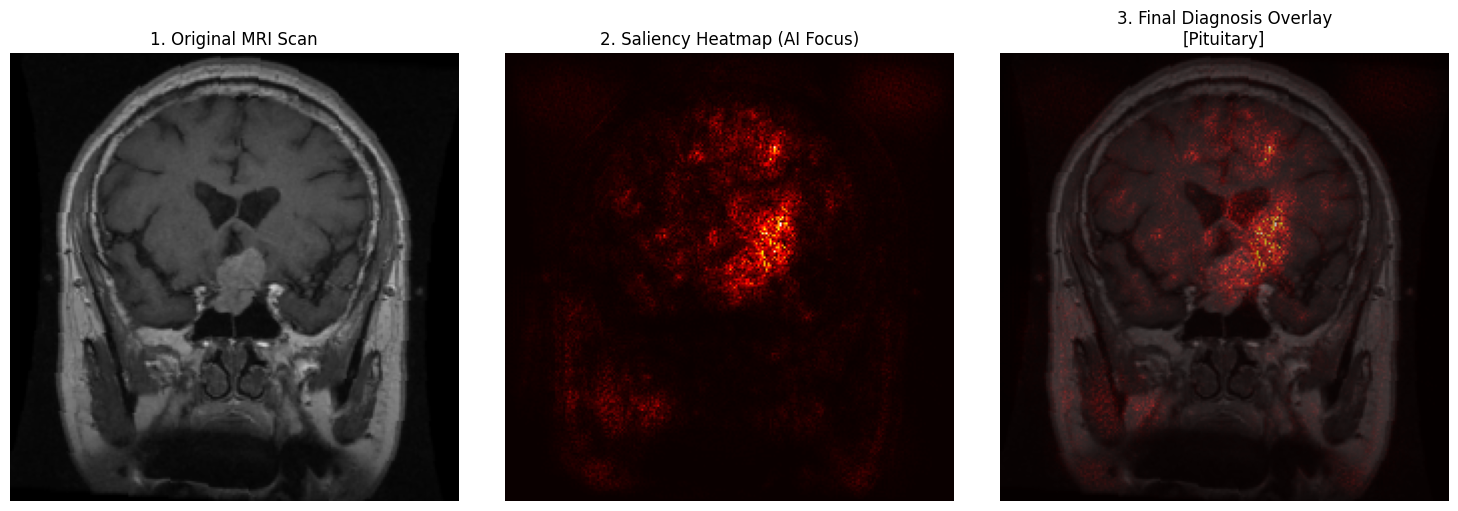

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch

class_names = ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']

def predict_and_visualize(image_tensor, true_label=None):
    model.eval()

    # 1. Prepare image and tell PyTorch to track the math (gradients)
    img_tensor = image_tensor.unsqueeze(0).to(device)
    img_tensor.requires_grad_()

    # 2. Run Inference
    _, cls_out = model(img_tensor)

    # 3. Get Classification Prediction
    pred_idx = torch.argmax(cls_out, dim=1).item()
    pred_class = class_names[pred_idx]

    # 4. Generate Saliency Saliency Heatmap (Explainable AI)
    score = cls_out[0, pred_idx]
    model.zero_grad()
    score.backward() # Trace back to the image

    # Extract the hot spots
    saliency, _ = torch.max(img_tensor.grad.data.abs(), dim=1)
    saliency = saliency.squeeze().cpu().numpy()

    # Normalize for clean display
    saliency = (saliency - saliency.min()) / (saliency.max() - saliency.min() + 1e-8)

    # 5. Process Original Image
    img_display = image_tensor.permute(1, 2, 0).cpu().detach().numpy()
    img_display = np.clip(img_display * 0.5 + 0.5, 0, 1)

    # Print Official Output
    print("-" * 50)
    print("AI DIAGNOSIS & EXPLAINABILITY REPORT")
    print("-" * 50)
    if true_label:
        print(f"Actual Scan Type : {true_label}")
    print(f"Predicted Type   : {pred_class}")
    print("Conclusion       : The heatmap overlay shows the exact structural anomalies the AI analyzed to make this classification.")
    print("-" * 50)

    # 6. Plotting
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(img_display)
    plt.title("1. Original MRI Scan")
    plt.axis('off')

    plt.subplot(1, 3, 2)
    # Using 'hot' to clearly show the AI's exact focal points
    plt.imshow(saliency, cmap='hot')
    plt.title("2. Saliency Heatmap (AI Focus)")
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(img_display)
    # Overlay the heatmap on the brain
    plt.imshow(saliency, cmap='hot', alpha=0.6)
    plt.title(f"3. Final Diagnosis Overlay\n[{pred_class}]")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

# Run the test on a sample
sample_images, sample_labels = next(iter(test_loader))
actual_name = class_names[sample_labels[3].item()]
predict_and_visualize(sample_images[3], true_label=actual_name)